In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx

# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import xarray
import ICIW_Plots

from ipywidgets import Dropdown, IntSlider, interact

plt.style.use("ICIWstyle")

In [2]:
from HSA_Cam_C_001_numpyro import (
    kl_divergence_between_models,
)
from HSA_Mo_C_001_numpyro import (
    kinetics_model,
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    sample_prior,
    sample_posterior,
    validate_against_holdout,
    TRUE_PARAMS,
)

In [3]:
# exp_run_name = "scornful-placebo"  # VI small test
exp_run_name = "terminal-microprocessor"  # full run with optimized settings
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [4]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)

In [5]:
for i, idata in enumerate(idatas):
    if i == 0:
        idata.add_groups({"prior": sample_prior(4000).prior})
    else:
        idata.add_groups({"prior": idatas[i - 1].posterior})

In [6]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [7]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [8]:
display(proposals)

array([[4.97621730e+02, 4.84634998e+00, 1.26041870e+00, 5.26943551e+02,
        2.70973036e+02, 8.59732766e-01],
       [5.29652460e+02, 6.98228646e+00, 2.50942976e+00, 5.73180267e+02,
        5.33639147e+01, 9.02142958e-01],
       [5.83828553e+02, 6.57343319e+00, 1.60528493e+00, 1.31750580e+02,
        6.72409754e+02, 2.36625497e-01],
       [5.35321728e+02, 5.90935894e+00, 3.21771063e+00, 2.06681822e+02,
        4.29446569e+02, 6.82665924e-01],
       [4.61511671e+02, 4.49393659e+00, 1.77429432e+00, 8.13589256e+02,
        7.31901683e+02, 6.07241485e-01],
       [5.97578186e+02, 3.45320080e+00, 1.38398688e+00, 7.70882702e+02,
        1.93278232e+02, 1.81853560e-01],
       [5.20914673e+02, 8.00232733e+00, 1.39757691e+00, 8.98647226e+02,
        4.47148518e+02, 4.94005139e-01],
       [4.83318232e+02, 5.64238586e+00, 9.14911703e-01, 8.10834582e+02,
        3.37599439e+02, 8.27528071e-02],
       [4.91848440e+02, 7.41669226e+00, 2.34410034e+00, 4.04554833e+02,
        1.46973761e+02, 

### Visualize the training success

In [9]:
@interact(
    i=IntSlider(
        min=0,
        max=proposals.shape[0] - 1,
        step=1,
        value=0,
        description="Experiment Index",
    ),
    j=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    ),
)
def interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$t$ / h",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
        # yscale="log",
        # ylim=(1e-6, 1e-5),
        # xlim=(450, 600),
    )

    T_prop = proposals[j : j + 1, 0:1]
    p_prop = proposals[j : j + 1, 1:2]
    c2h_prop = proposals[j : j + 1, 2:3]
    c2m_prop = proposals[j : j + 1, 3:4]
    c2w_prop = proposals[j : j + 1, 4:5]
    c2i_prop = proposals[j : j + 1, 5:6]

    pi_prop = calculate_partial_pressures(
        p_total=p_prop,
        c2h_ratio=c2h_prop,
        c2m_ratio=c2m_prop,
        c2w_ratio=c2w_prop,
        c2i_ratio=c2i_prop,
    )

    r_pred = predict(
        idatas[i],
        T_prop,
        pi_prop,
        key="prior" if i == 0 else "posterior",
    )
    display(i, j)
    display(r_pred.shape)

    ax.plot(r_obs[:, j, 0, 0], "ro", label="Observed data")
    ax.plot(r_pred.mean(axis=3)[:, 0, 0], label="Predicted data")
    ax.fill_between(
        jnp.arange(r_pred.shape[0]),
        jnp.quantile(r_pred[:, 0, 0, :], 0.05, axis=1),
        jnp.quantile(r_pred[:, 0, 0, :], 0.95, axis=1),
        color="gray",
        alpha=0.5,
        label="90% credible interval",
    )

interactive(children=(IntSlider(value=0, description='Experiment Index', max=31), IntSlider(value=0, descripti…

16

16

(10, 1, 1, 25)

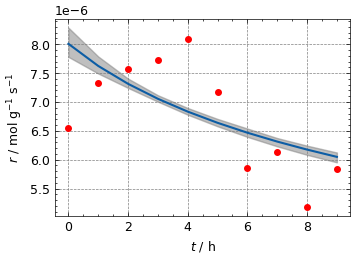

In [10]:
interactive(16, 16)  # (10,0) & (16,16)
fig = plt.gcf()
plt.savefig("figures/ODE_example_1.svg")

### Visualize the experimental plan

/tmp/ipykernel_6310/2292498082.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


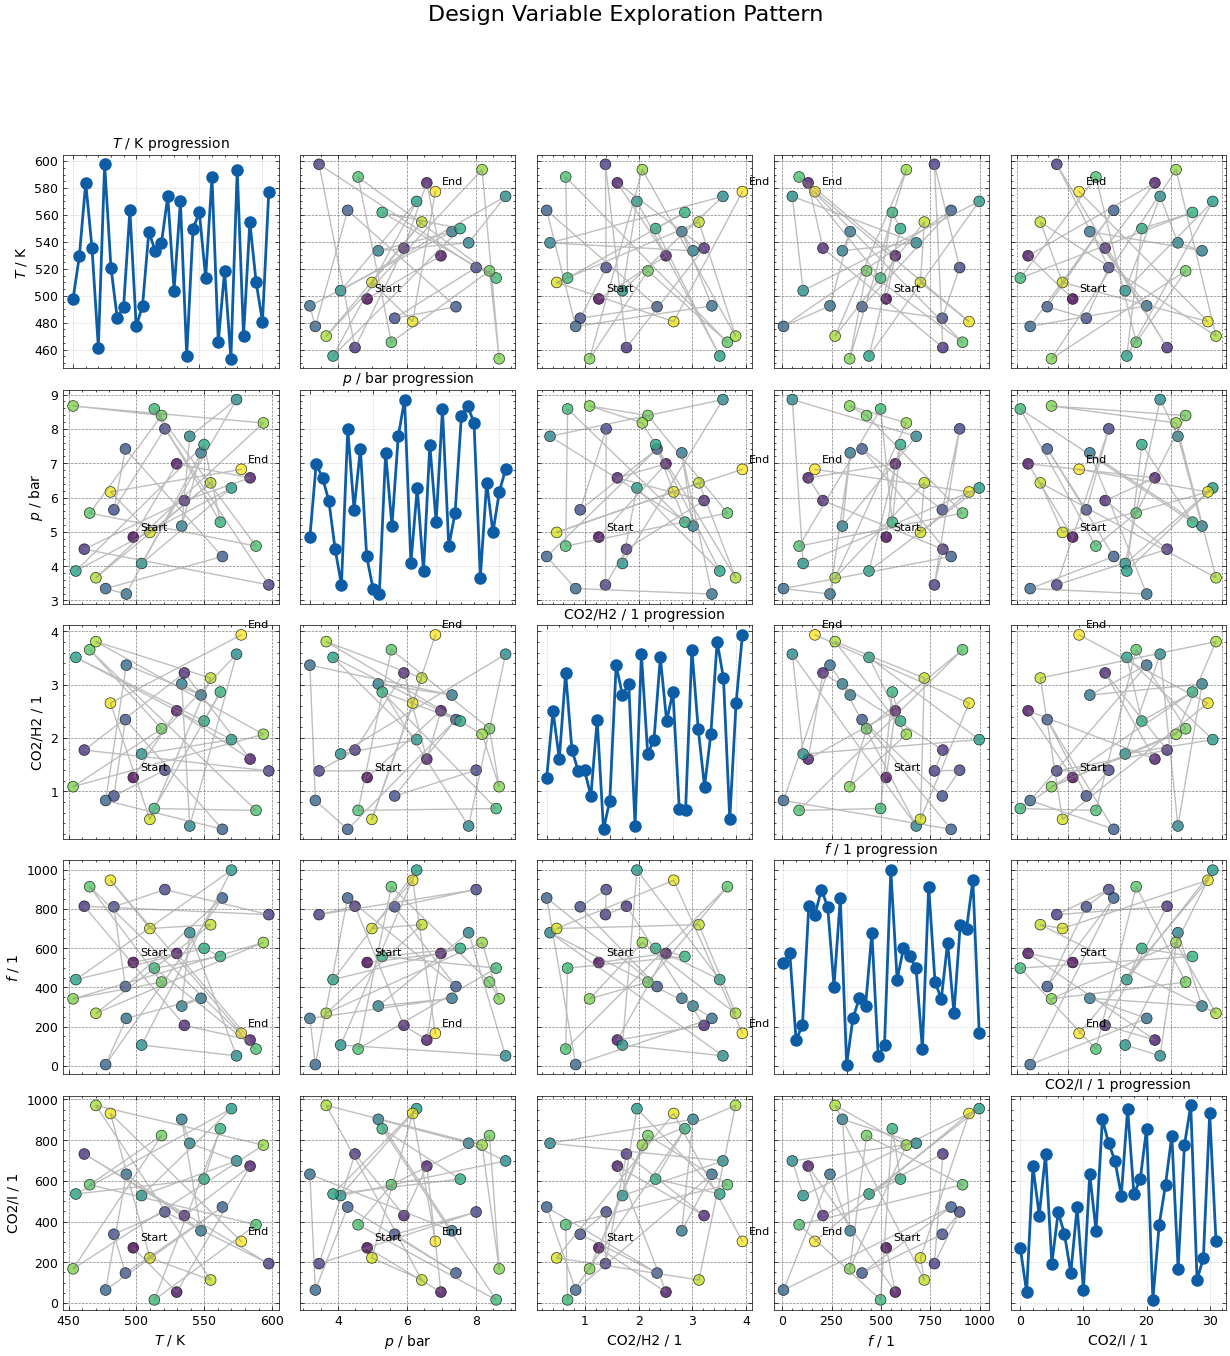

In [11]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = [r"$T$ / K", r"$p$ / bar", r"CO2/H2 / 1", r"$f$ / 1", r"CO2/I / 1"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

### Observe the parameter progression

In [12]:
print(list(idatas[0].posterior.data_vars))


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    )
)
def interactive(key):
    az.plot_density(
        [idata for idata in idatas],
        group="posterior",
        var_names=key,
        shade=0.2,
    )

['Ea_deact', 'Ea_k', 'k0', 'k_deact', 'n_deact', 'r_lat', 'sigma_r', 't_Ea_deact', 't_Ea_k', 't_k0', 't_k_deact', 't_n_deact']


interactive(children=(Dropdown(description='Parameter:', index=2, options=('Ea_deact', 'Ea_k', 'k0', 'k_deact'…

In [13]:
az.summary(idatas[-1])

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Ea_deact[0],34105.485,2946.586,28579.010,39698.898,40.502,52.489,5227.0,2738.0,1.0
Ea_k[0],77113.398,416.047,76328.115,77874.283,5.875,7.618,5023.0,2677.0,1.0
k0[0],0.000,0.000,0.000,0.000,0.000,0.000,5471.0,2918.0,1.0
k_deact[0],0.000,0.000,0.000,0.000,0.000,0.000,4914.0,2694.0,1.0
n_deact[0],5.194,0.646,3.957,6.340,0.010,0.012,4221.0,2429.0,1.0
...,...,...,...,...,...,...,...,...,...
t_Ea_deact,-0.030,0.086,-0.194,0.134,0.001,0.002,5227.0,2738.0,1.0
t_Ea_k,0.433,0.005,0.423,0.443,0.000,0.000,5023.0,2677.0,1.0
t_k0,1.221,0.016,1.192,1.253,0.000,0.000,5471.0,2918.0,1.0
t_k_deact,0.964,0.188,0.627,1.324,0.003,0.003,4914.0,2694.0,1.0


In [14]:
@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
    i=IntSlider(
        min=0,
        max=len(idatas) - 1,
        step=1,
        value=0,
        description="Inference Step",
    ),
)
def interactive(key, i):
    az.plot_dist_comparison(
        idatas[i],
        var_names=key,
    )

interactive(children=(Dropdown(description='Parameter:', index=2, options=('Ea_deact', 'Ea_k', 'k0', 'k_deact'…

### Validate against holdout data

In [15]:
test_data = xarray.open_dataset(Path("data/test_HSA_Da_C_001.nc"))
display(test_data)

<xarray.Dataset> Size: 160kB
Dimensions:    (sample: 1000, parameter: 6, species: 5, time: 10, component: 1,
                draws: 1)
Coordinates:
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
  * time       (time) int64 80B 0 1 2 3 4 5 6 7 8 9
  * component  (component) <U1 4B 'a'
  * draws      (draws) int64 8B 0
Data variables:
    samples    (sample, parameter) float64 48kB ...
    T          (sample) float32 4kB ...
    p          (sample, species) float32 20kB ...
    latent_r   (time, sample, component, draws) float32 40kB ...
    obs_r      (time, sample, component, draws) float32 40kB ...
Attributes:
    noise:    homoscedastic
    sigma:    1e-05

In [16]:
postdatas = []
for idata in idatas:
    postdata = validate_against_holdout(idata, test_data, num_samples=985)
    postdatas.append(postdata)

(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


(1000, 1) (1000, 5) None


...

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


In [17]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[
        var_name
    ].values  # shape (chain=1, draw=1, obs, times=10, 1)
    pred = postdata.posterior_predictive[
        var_name
    ].values  # shape (chain=1, draw, obs, times=10, n_samples)
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=(2, 3, 4))).squeeze()
    rmse_da = xarray.DataArray(
        data=rmse_vals,
        dims=["draw"],
    )
    return rmse_da

In [18]:
RMSEs = []
for postdata in postdatas:
    RMSEs.append(bRMSE(postdata, "r_lat"))

RMSEs = np.array(RMSEs)

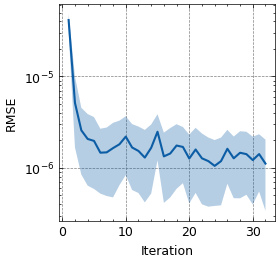

In [19]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
)
ax.plot(np.arange(1, len(RMSEs) + 1), RMSEs.mean(axis=1))
ax.fill_between(
    np.arange(1, len(RMSEs) + 1),
    np.quantile(RMSEs, 0.025, axis=1),
    np.quantile(RMSEs, 0.975, axis=1),
    alpha=0.3,
)

### Quantify information gain

In [20]:
info_gains = []
for i in range(0, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[i],
        key_new="posterior",
        key_old="prior",
        var_names=[
            "k0",
            "Ea_k",
            "k_deact",
            "Ea_deact",
            "n_deact",
            "sigma_r",
        ],
    )
    info_gains.append(klds)
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

[ 1.60860171  1.85634863  0.62644739  2.0763715   0.19798069 28.6581214 ]
35.023871314921564
[16.28164552 13.93840397  0.30092621  0.06305272  0.73293511  4.0669182 ]
35.38388173315554
[0.56429227 0.47474538 0.09102994 0.02762915 0.1492577  0.49660223]
1.8035566751846717
[0.13179831 0.02755268 0.09443179 0.00866599 0.051467   0.20406104]
0.5179768071176555
[0.02873718 0.19580387 0.05889742 0.02893227 0.01673178 0.0314202 ]
0.36052272136087404
[0.11111324 1.3771495  0.0292608  0.00275761 0.13439378 0.02113933]
1.675814261625592
[0.02600456 0.21960744 0.05799284 0.00664267 0.05951629 0.66766241]
1.0374262132567238
[0.03645099 0.45170512 0.04451701 0.02652138 0.07287038 0.08845284]
0.720517720316081
[0.04267837 0.01430261 0.070704   0.00786774 0.36486597 0.15835423]
0.658772932538503
[0.16356696 0.06014954 0.93825361 0.09251245 1.63529727 0.01021733]
2.8999971775949622
[0.91359368 1.82263779 1.83531246 0.19830373 1.39782196 0.29120082]
6.4588704401983925
[0.10800036 0.42335646 0.02254334 

Text(0, 0.5, 'info gain as per KL divergence')

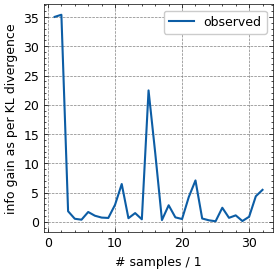

In [21]:
plt.plot(np.arange(len(kldses)) + 1, kldses, label="observed")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

In [22]:
info_gains = []
for i in range(0, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[0],
        key_new="posterior",
        key_old="prior",
        var_names=[
            "k0",
            "Ea_k",
            "k_deact",
            "Ea_deact",
            "n_deact",
            "sigma_r",
        ],
    )
    info_gains.append(klds)
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

[ 1.52601772  1.88791212  0.67387287  2.05191434  0.21932334 10.66117337]
17.020213765661154
[ 3.03604059  3.02841869  0.62628924  2.07649529  0.16600032 31.56314711]
40.496391242557685
[ 3.64468174  3.63449784  0.62486074  2.05315818  0.34259308 31.60036209]
41.90015366936353
[ 3.65205025  3.64185     0.96465323  2.00916371  0.54050103 31.59945373]
42.40767194520612
[ 3.49505911  3.30086825  1.10638145  2.16824134  0.5497141  31.62457435]
42.2448385884645
[ 3.89322557  4.21030277  1.14677052  2.13401359  0.83868444 31.65674695]
43.87974384162153
[ 3.78841044  3.51322947  1.27310522  2.14380423  0.73191042 31.72361221]
43.174071988882005
[ 3.74879818  3.1522679   1.3750314   2.08515941  0.91031363 31.76286865]
43.03443917140454
[ 3.83803399  4.03017677  1.20465505  2.11169118  0.60798902 31.76495559]
43.5575015986292
[ 4.06514086  4.37388656  1.04654722  2.13794233  0.94583288 31.7725562 ]
44.34190604326897
[ 3.8096988   3.72386957  1.37062096  2.08412291  0.88930406 31.78228462]
43.65

Text(0, 0.5, 'info gain as per KL divergence')

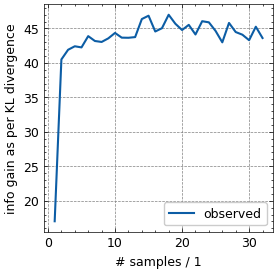

In [23]:
plt.plot(np.arange(len(kldses)) + 1, kldses, label="observed")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")